# Tinless system optimizer

Finds the plant design with the lowest **lifetime cost** = lifetime capex (initial + cell replacements +
bare-area cleanings, all +30% soft costs) + the lifetime cost of the **energy lost**, at one electricity
price for charge and discharge. Net round-trip efficiency = (AC out − floor-cooling and heat-rejection
fans) / AC in, incl. hold losses. Capex is reported on its own; the capex–efficiency Pareto front is
read from the logs. An optional RTE floor is available. Model: `thermal/optimize.py`.

Per design: **shade-open sizing** on the clean discharge (T_max is the variable; T_min = the volume-average
block temperature at which the shades are fully open, block volume so that happens at the target duration;
deposition per cycle from the final run, none while the stick is retracted during charge and hold) →
heater cavity (smallest that charges in `charge_hr`) → tank sized on the clean stick (AC basis, energy
target enforced) → stick discharge at the end of a
replacement interval (cells replaced at D = 0.1, bare areas cleaned at D = 0.01) → capex, efficiency
and cost of the energy lost with the interval-average performance.

* **Physics inputs** (materials, emissivities, bandgap, liner / shade / axial-radiation switches, stick
  temperature, gaps, liner thickness, RGF pad, timesteps, heater size / max T / power) come from
  `tinless_model_input.yaml`: edit them in the YAML cell of `tinless system model.ipynb` and run it.
* **Costs, efficiencies, maintenance thresholds, ranges and fidelity** are in the inputs cell below.
* **Optimized variables**: `thermal.optimize.DESIGN_VARS` (printed below).

In [1]:
import os, glob, json, time, copy
import numpy as np
import matplotlib.pyplot as plt
from thermal import optimize as O
from thermal.build import load_config

base_cfg = load_config('tinless_model_input.yaml')
print(f"Base YAML: L {base_cfg['storage']['L']} m, block {base_cfg['storage'].get('block_height')} m, "
      f"liner {base_cfg['powerstick']['liner_side_len']} m, heater {base_cfg['heater']['side_len']} m / "
      f"{base_cfg['heater']['max_temperature']} K / {base_cfg['heater']['max_power_per_m']/1e3:.0f} kW/m (power cap; "
      f"the optimizer sizes each heater's power and cavity for charge_hr)")

Base YAML: L 3 m, block 10 m, liner 0.25 m, heater 0.15 m / 2873 K / 150 kW/m (power cap; the optimizer sizes each heater's power and cavity for charge_hr)


In [2]:
# -- Inputs (not optimized) ------------------------------------------------------
OPT_INPUTS = {
    'P_rated': 25.0e6,            # W AC export
    'duration_hr': 50.0,          # h at P_rated: energy target, enforced on clean performance
    'charge_hr': 50.0,            # h design charge time (heater power, then cavity, sized to meet it)
    'economics': {
        'eta_out': 0.98,          # DC -> AC inverter
        'eta_in': 0.98,           # AC -> heater supply
        'cycles_per_year': 8760.0 / 168.0,   # 1-week cycle: 50 h charge + hold + 50 h discharge
        'lifetime_yr': 30.0,
        'soft_cost_frac': 0.30,   # tax, freight, soft costs on all capex (incl. replacements)
        'elec_price': 75.0,       # $/MWh, same for charge and discharge: prices the energy lost
    },
    'objective': {'rte_min': 0.0},    # optional floor on net RTE (0 = none)
    'costs': {
        'cell_per_cm2': 1.0,      # $/cm2 cell-covered powerstick face (also each replacement)
        'stick_per_m': 100.0,     # $/m stick length
        'stick_fixed': 2000.0,    # $/stick
        'heater_fixed': 5000.0,   # $/heater element
        'charge_electrics_per_kW': 75.0,   # $/kW heater supply
        'inverter_per_kW': 100.0,          # $/kW_AC, sized on peak plant output (>= P_rated)
        'heat_rejection_per_kWth': 125.0,  # $/kW_th dry cooler, sized on peak stick heat rejection
        'bare_clean_per_stick': 0.0,       # $/stick per bare-area cleaning (count is tracked)
        'interconnect_per_kW': 150.0,      # $/kW grid connection, sized on max(peak charge, peak output) AC
                                           #   (LBNL: completed storage projects avg ~$151/kW) PLACEHOLDER
    },
    'parasitics': {'heat_rejection_kWe_per_kWth': 0.03},   # dry-cooler fans + pumps; floor fans from the tank model
    'deposition': {
        'd_dead_nm': 10.0,        # linear: cells dead and bare / inactive emissivity at emis_end at 10 nm
        'emis_end': 0.8,
        'cell_replace_D': 0.1,    # replace cells at this degradation
        'bare_clean_D': 0.01,     # clean bare areas at this degradation
    },
    'geometry': {
        'ps_liner_gap': 0.02,     # m min powerstick -> liner clearance per side
        'heater_min_gap': 0.25,   # m min heater -> cavity wall clearance
        'H_max': 12.0,            # m block height upper bound
        'T_cap_C': 2500.0,        # C max block temperature (heater max 2600 C in the YAML)
        'T_min_floor_C': 1400.0,  # C lowest allowed T_min (T_min comes from the shade-open sizing)
        'min_wall': 0.30,         # m min graphite wall between neighbouring cavities (stick cavities at 45 deg)
        'swing_min': 200.0, 'swing_max': 1000.0,   # C allowed swing
    },
    # shade-open sizing: shades must open within tol_T [K] of T_min and tol_t of the duration
    'sizing': {'tol_T': 3.0, 'tol_t': 0.01, 'max_iter': 6, 'swing_guess': 500.0},
    'limits': {'D_tank_max': 80.0, 'H_tank_max': 30.0},
    'fidelity': {'dz': 0.5, 'nrad': 5, 'dt_scale': 2.0, 'vane_rays': 2 ** 12, 'heater_ar_tol': 0.03},
}
opt = O.merge(O.OPT_DEFAULTS, OPT_INPUTS)

print('Optimized variables:')
for name, lo, hi, integer, desc in O.DESIGN_VARS:
    print(f"  {name:11s} [{lo:g}, {hi:g}]{' int' if integer else '    '}  {desc}")

Optimized variables:
  liner_side  [0.2, 0.6]      liner side length [m]
  ps_frac     [0, 1]      powerstick side: 0.10 m + frac x (room in liner - 0.10)
  L           [1, 5]      stick length [m]
  H_frac      [0, 1]      block height: L + frac x (H_max - L)
  avg_flux    [5, 20]      cell flux target [W/cm2] (continuous)
  shade_8th   [2, 24] int  shade thickness i x 1/8 in (1/4 - 3 in)
  t_side      [0.5, 2]      tank side insulation [m]
  t_top       [0.5, 2]      tank top insulation [m]
  T_max_C     [1600, 2500]      block T_max [C] (capped at geometry.T_cap_C); T_min from shade-open sizing


In [3]:
# -- Baseline: the design currently in the YAML -----------------------------------
baseline = O.design_from_cfg(base_cfg)
_t0 = time.perf_counter()
res_base = O.evaluate(baseline, base_cfg, opt)
print(f"({time.perf_counter() - _t0:.0f} s)")
print(O.summary(res_base))

(44 s)
Design: liner 250 mm, powerstick 130 mm, L 3.00 m, block H 10.00 m, flux 10.0 W/cm2, shade 1.54 in, insulation side 1.00 / top 1.50 m, T_max 2100 C
Plant: 410 sticks + heaters, hot zone 52.9 m, tank 55.0 x 20.0 m; block r 0.661-1.218 m, T 1827-2100 C (shade-open sizing: volume x1.055, 4 runs); heater 150 kW, cavity 691 mm (area_ratio 3.62)
Grid: pitch 1.587 m, graphite walls stick-heater 507, stick-stick 1206, heater-heater 1553 mm (stick cavities at 45 deg)
Cycle: charge 49.3 h, hold 69.7 h, discharge 50.5 h clean / 47.5 h end of interval; energy vs target +1.1% (clean); losses 1.70 %/day
Per stick: 3,182 kWh clean -> 2,660 kWh at D_cell 0.10 / D_bare 0.01; deposition 0.97 pm/cycle
Maintenance: 1 cell replacements (every 19.7 yr), 14 bare-area cleanings besides (every 2.0 yr)
Flux (clean): 30% of stick-in time above target, 70% at target, 0% below; std 0.69 W/cm2, rms about target 0.78, max 13.2, end 10.0
Per cycle: out 1,160 MWh AC - fans 3.3 floor / 50.1 heat rejection = 1,10

In [4]:
# -- Differential evolution ------------------------------------------------------
# ~1-2 min per design on one core (shade-open sizing: ~3-4 discharges); WORKERS designs in
# parallel. Each generation = POPSIZE x 9 designs. Every evaluation is logged to LOG_DIR (load it below while a run is going).
# The capex-efficiency Pareto plot below pools every run under opt_runs/.
RUN_DE   = False
WORKERS  = 20
POPSIZE  = 10             # x 9 variables = 90 designs / generation
MAXITER  = 25
SEED     = 0
LOG_DIR  = os.path.join('opt_runs', time.strftime('%Y%m%d_%H%M%S') + f"_p{opt['economics']['elec_price']:.0f}")

if RUN_DE:
    _t0 = time.perf_counter()
    _gen = [0]

    def _cb(xk, convergence):          # once per generation: best feasible design so far (from the log)
        _gen[0] += 1
        rows = O.load_log(LOG_DIR)
        feas = [r for r in rows if r.get('feasible')]
        if feas:
            b = min(feas, key=lambda r: r['lifetime_cost'])
            best_txt = (f"${b['lifetime_cost']/1e6:,.1f}M (capex ${b['capex_total']/1e6:,.1f}M, "
                        f"RTE {b['RTE']*100:.1f}%)")
        else:
            best_txt = 'none feasible yet'
        print(f"gen {_gen[0]:3d}  {(time.perf_counter() - _t0)/60:6.1f} min  {len(rows)} designs  "
              f"best {best_txt}  convergence {convergence:.3f}", flush=True)

    x0 = O.encode(baseline, opt)
    de = O.run_de(base_cfg, opt, LOG_DIR, maxiter=MAXITER, popsize=POPSIZE, workers=WORKERS, seed=SEED,
                  x0=x0, callback=_cb)
    print(f"done in {(time.perf_counter() - _t0)/60:.1f} min, {de.nfev} designs; best f {de.fun:.2f}")
    with open(os.path.join(LOG_DIR, 'inputs.json'), 'w') as fh:
        json.dump(dict(opt=opt, base_yaml='tinless_model_input.yaml', de=dict(fun=de.fun, x=list(de.x))), fh,
                  indent=1, default=str)

0 designs evaluated, 0 feasible, 0 failed


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_286868\2204203875.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].grid(alpha=.3); ax[0].legend(fontsize=8); ax[0].set_title('Capex vs efficiency')


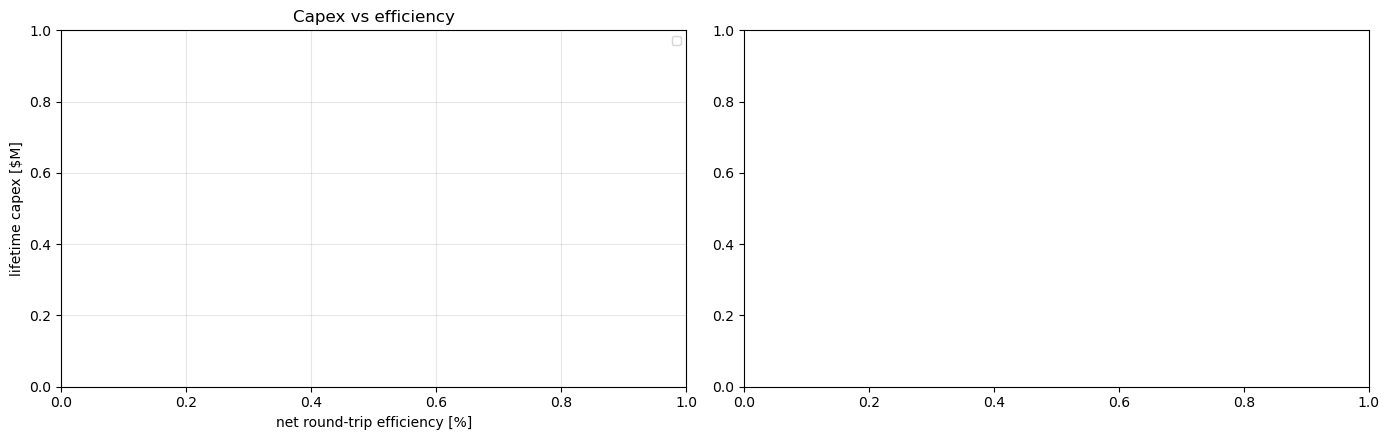

In [5]:
# -- Results: best designs in a run, and the capex-efficiency front ---------------
# Point LOG_DIR at any run folder under opt_runs/ to reload it.
rows = O.load_log(LOG_DIR)
ok = [r for r in rows if r.get('feasible')]
print(f"{len(rows)} designs evaluated, {len(ok)} feasible, {sum('error' in r for r in rows)} failed")
best = sorted(ok, key=lambda r: r['lifetime_cost'])[:10]
for i, r in enumerate(best):
    print(f"\n#{i+1}  (f {r['f']:.2f})")
    print(O.summary(r))

# Pareto front (designs whose only violation is the RTE floor count). Add other run folders
# to PARETO_DIRS only if they used the same model and inputs.
PARETO_DIRS = [LOG_DIR]
all_rows = [r for d in PARETO_DIRS for r in O.load_log(d)]
pool = [r for r in all_rows if 'capex_total' in r and set(r.get('violations') or {}) <= {'rte'}]
front = O.pareto(all_rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
if pool:
    ax[0].scatter([r['RTE'] * 100 for r in pool], [r['capex_total'] / 1e6 for r in pool], s=8, alpha=.35,
                  label='feasible except RTE floor')
    ax[0].plot([r['RTE'] * 100 for r in front], [r['capex_total'] / 1e6 for r in front], 'o-', c='C3', ms=4,
               label='Pareto front')
    ax[0].axvline(opt['objective']['rte_min'] * 100, c='k', ls=':', lw=.8, label='this run RTE floor')
ax[0].set_xlabel('net round-trip efficiency [%]'); ax[0].set_ylabel('lifetime capex [$M]')
ax[0].grid(alpha=.3); ax[0].legend(fontsize=8); ax[0].set_title('Capex vs efficiency')
if best:
    b = best[0]
    parts = {k.split(' (')[0]: v * (1 + opt['economics']['soft_cost_frac']) for k, v in b['capex_lines'].items()}
    parts['cell replacements'] = b['n_rep'] * b['rep_cost']
    parts['bare cleanings'] = b['n_clean'] * b['clean_cost']
    ax[1].barh(list(parts), np.array(list(parts.values())) / 1e6)
    ax[1].set_xlabel('$M incl. soft costs'); ax[1].invert_yaxis(); ax[1].grid(alpha=.3, axis='x')
    ax[1].set_title(f"Best: capex ${b['capex_total']/1e6:,.1f}M, RTE {b['RTE']*100:.1f}% "
                    f"(+ energy lost ${b['loss_cost']/1e6:,.1f}M)")
plt.tight_layout(); plt.show()

In [6]:
# -- Variable scatter: each optimized variable vs objective (capex + energy lost; colour = RTE) --
if ok:
    keys = ['liner_side', 'ps_side', 'L', 'H_block', 'avg_flux', 'shade_thickness', 't_side', 't_top',
            'T_max_C', 'T_min_C', 'swing']           # last two: sizing outputs
    fig, axs = plt.subplots(3, 4, figsize=(16, 10))
    v = np.array([r['lifetime_cost'] for r in ok]) / 1e6
    e = np.array([r['RTE'] for r in ok]) * 100
    for ax, k in zip(axs.flat, keys):
        sc = ax.scatter([r['design'].get(k, r.get(k)) for r in ok], v, c=e, s=8, alpha=.6, cmap='viridis')
        ax.set_xlabel(k); ax.grid(alpha=.3)
    axs.flat[-1].axis('off')
    fig.colorbar(sc, ax=axs.flat[-1], label='net RTE [%]')
    for ax in axs[:, 0]:
        ax.set_ylabel('capex + energy lost [$M]')
    plt.tight_layout(); plt.show()

C:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:523: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
C:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:624: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=2098 K reached cutoff 2101 K at t=50.5000 hr (181800.0 s) — powerstick removed, conduction-only phase begins.


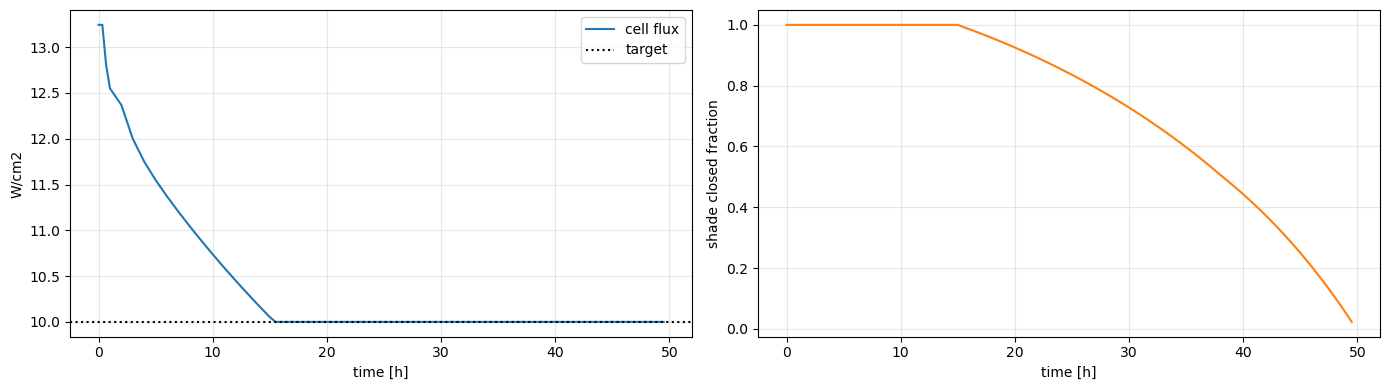

{'Q_rej_peak': 98181.304, 'E_rej': 13809246967.993, 'P_elec_peak': 82728.285, 't_on_hr': 49.5, 'flux_target': 10.0, 'E_rad': 25262875127.878, 'E_sink': 633756879.348, 'E_released': 25896632007.226, 'frac_above': 0.303, 'frac_band': 0.697, 'frac_below': 0.0, 'E_frac_above': 0.327, 'E_frac_below': 0.0, 'flux_mean': 10.351, 'flux_std': 0.692, 'flux_rms_dev': 0.776, 'flux_max': 13.244, 'flux_end': 10.0, 'P_elec_end': 62038.098}


In [7]:
# -- Cell-flux band of a design: time above / at / below the target (clean cells) ---------
# Re-runs the clean discharge of the best feasible design (or the baseline).
_r = best[0] if best else res_base
_cfg = O.design_cfg(base_cfg, _r['design'], opt)
_cfg['heater']['area_ratio'] = _r.get('heater_area_ratio', _cfg['heater'].get('area_ratio'))
if 'T_min_C' in _r:                                   # the sized block
    _cfg['storage']['T_min'] = _r['T_min_C'] + 273.15
    _cfg['storage']['block_temp_range'] = _r['swing']
    _cfg['storage']['volume_factor'] = _r['volume_factor']
_m, _run, _st, _fm = O._discharge(_cfg, opt, deposition=False)
_ps = _m.powerstick
_A = 4 * _ps.width * _ps.height * (1 - _ps.f_bare) * _ps.f_active * 1e4
_t = _run['time'] / 3600
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(_t, _run['Q_cell'] / _A, label='cell flux')
ax[0].axhline(_m.avg_flux, c='k', ls=':', label='target')
ax[0].set_xlabel('time [h]'); ax[0].set_ylabel('W/cm2'); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(_t, _run['f_shade'], c='C1'); ax[1].set_xlabel('time [h]'); ax[1].set_ylabel('shade closed fraction')
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in _fm.items() if isinstance(v, float)})

In [8]:
# -- Verify the top designs at detailed settings (0.33 m rings, 2^14 rays, full timestep) --
N_VERIFY = 3
for i, r in enumerate(best[:N_VERIFY]):
    _t0 = time.perf_counter()
    rv = O.evaluate(r['design'], base_cfg, opt, fidelity=O.DETAILED)
    print(f"\n#{i+1} detailed ({time.perf_counter() - _t0:.0f} s): objective ${rv.get('lifetime_cost', np.nan)/1e6:,.1f}M "
          f"vs screening ${r['lifetime_cost']/1e6:,.1f}M; RTE {rv.get('RTE', np.nan)*100:.1f}% vs {r['RTE']*100:.1f}%; "
          f"feasible {rv.get('feasible')} {rv.get('violations')}")
    print(O.summary(rv))